# 📊 Customer Churn Prediction — EDA & Model Experiments

Notebook lưu vết toàn bộ quá trình khám phá dữ liệu (EDA), tiền xử lý, huấn luyện, so sánh và trực quan hóa 4 mô hình Machine Learning trên tập dữ liệu **Telco Customer Churn**.

---

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import xgboost as xgb
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from xgboost import XGBClassifier

from src.data_loader import (
    CATEGORICAL_FEATURES,
    NUMERICAL_FEATURES,
    clean_data,
    get_train_test_data,
    load_raw_data,
)
from src.pipeline import build_full_pipeline, build_preprocessor

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

C:\Users\MY MSI\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Phần 1: EDA & Khám phá dữ liệu

### 1.1 Đọc dữ liệu thô và kiểm tra kiểu dữ liệu, giá trị thiếu

In [2]:
raw_df = load_raw_data()
print(f"Kích thước dữ liệu: {raw_df.shape[0]} dòng, {raw_df.shape[1]} cột")
raw_df.head()

Kích thước dữ liệu: 7043 dòng, 21 cột


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
explicit_missing = raw_df.isnull().sum()
blank_total_charges = (raw_df["TotalCharges"].astype(str).str.strip() == "").sum()

print("Giá trị NaN tường minh theo từng cột:")
print(explicit_missing[explicit_missing > 0] if explicit_missing.sum() > 0 else "Không có NaN tường minh")
print(f"\nSố dòng có TotalCharges là chuỗi rỗng: {blank_total_charges}")
raw_df[raw_df["TotalCharges"].astype(str).str.strip() == ""][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Giá trị NaN tường minh theo từng cột:
Không có NaN tường minh

Số dòng có TotalCharges là chuỗi rỗng: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


### 1.2 Phân phối biến mục tiêu (`Churn`) — Kiểm tra mất cân bằng lớp

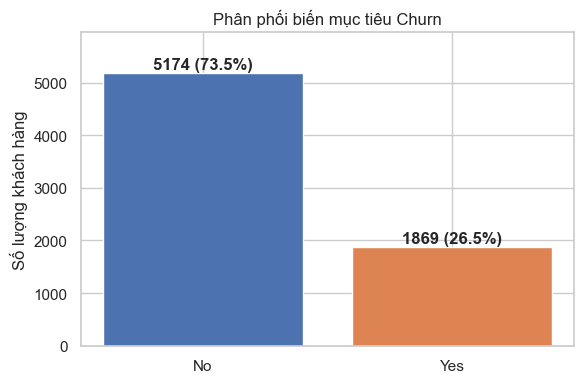

In [5]:
churn_counts = raw_df["Churn"].value_counts()
churn_ratios = raw_df["Churn"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(churn_counts.index, churn_counts.values, color=["#4C72B0", "#DD8452"])
for bar, pct in zip(bars, churn_ratios.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 80,
        f"{int(bar.get_height())} ({pct:.1f}%)",
        ha="center",
        fontweight="bold",
    )
ax.set_title("Phân phối biến mục tiêu Churn")
ax.set_ylabel("Số lượng khách hàng")
ax.set_ylim(0, churn_counts.max() * 1.15)
plt.tight_layout()
plt.show()

### 1.3 Mối quan hệ giữa `tenure`, `MonthlyCharges`, `Contract` với `Churn`

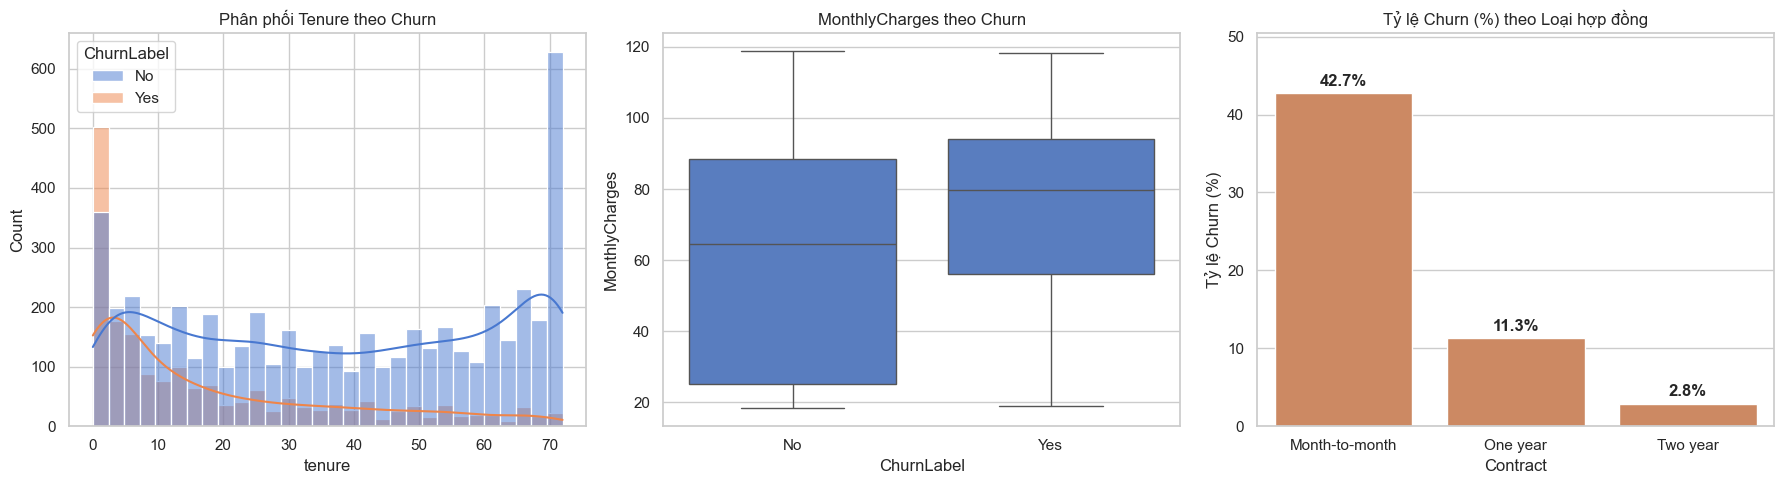

In [6]:
cleaned_df = clean_data(raw_df)
cleaned_df["ChurnLabel"] = cleaned_df["Churn"].map({0: "No", 1: "Yes"})

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=cleaned_df, x="tenure", hue="ChurnLabel", kde=True, bins=30, ax=axes[0])
axes[0].set_title("Phân phối Tenure theo Churn")

sns.boxplot(data=cleaned_df, x="ChurnLabel", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("MonthlyCharges theo Churn")

contract_churn = (
    cleaned_df.groupby("Contract")["Churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)
sns.barplot(x=contract_churn.index, y=contract_churn.values, ax=axes[2], color="#DD8452")
axes[2].set_title("Tỷ lệ Churn (%) theo Loại hợp đồng")
axes[2].set_ylabel("Tỷ lệ Churn (%)")
for idx, val in enumerate(contract_churn.values):
    axes[2].text(idx, val + 1, f"{val:.1f}%", ha="center", fontweight="bold")
axes[2].set_ylim(0, contract_churn.max() * 1.18)

plt.tight_layout()
plt.show()

--- 
## Phần 2: Data Preprocessing

Chia tập dữ liệu Stratified 80/20 và minh họa quá trình chuẩn hóa (`StandardScaler`) kết hợp mã hóa (`OneHotEncoder`) thông qua `ColumnTransformer`.

In [7]:
X_train, X_test, y_train, y_test = get_train_test_data()
print(f"X_train: {X_train.shape}, y_train Churn rate: {y_train.mean():.4f}")
print(f"X_test:  {X_test.shape}, y_test Churn rate:  {y_test.mean():.4f}")

preprocessor = build_preprocessor()
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print(f"Số chiều sau One-Hot + Scaling: {X_train_transformed.shape[1]} features")

X_train: (5634, 19), y_train Churn rate: 0.2654
X_test:  (1409, 19), y_test Churn rate:  0.2654
Số chiều sau One-Hot + Scaling: 46 features


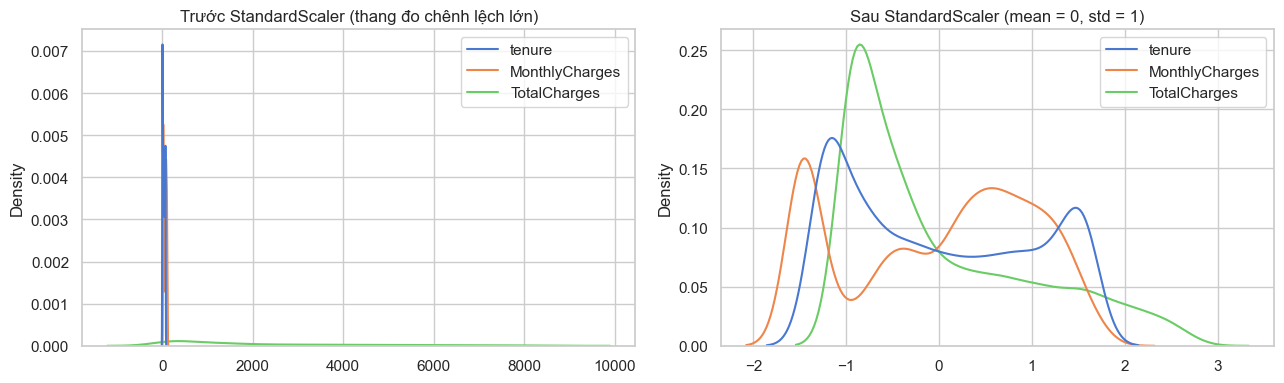

In [8]:
scaled_df = pd.DataFrame(
    X_train_transformed[:, : len(NUMERICAL_FEATURES)],
    columns=NUMERICAL_FEATURES,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.kdeplot(data=X_train[NUMERICAL_FEATURES], ax=axes[0])
axes[0].set_title("Trước StandardScaler (thang đo chênh lệch lớn)")

sns.kdeplot(data=scaled_df, ax=axes[1])
axes[1].set_title("Sau StandardScaler (mean = 0, std = 1)")

plt.tight_layout()
plt.show()

--- 
## Phần 3: Huấn luyện & So sánh mô hình

Thực nghiệm 4 thuật toán: **Logistic Regression**, **Random Forest**, **XGBoost**, **LightGBM** với xử lý mất cân bằng lớp (`class_weight="balanced"` / `scale_pos_weight`).

In [9]:
scale_pos_weight = (len(y_train) - y_train.sum()) / y_train.sum()

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=8,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=150,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric="logloss",
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=150,
        max_depth=5,
        learning_rate=0.05,
        class_weight="balanced",
        random_state=42,
        verbose=-1,
    ),
}

results = []
trained_pipelines = {}
probabilities = {}
predictions = {}

for name, estimator in models.items():
    pipeline = build_full_pipeline(estimator)
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    trained_pipelines[name] = pipeline
    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append(
        {
            "Model": name,
            "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4),
            "Recall": round(recall_score(y_test, y_pred), 4),
            "Precision": round(precision_score(y_test, y_pred), 4),
            "F1-Score": round(f1_score(y_test, y_pred), 4),
            "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        }
    )

results_df = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)
results_df

,Model,ROC-AUC,Recall,Precision,F1-Score,Accuracy
0,XGBoost,0.8435,0.8021,0.5291,0.6376,0.7580
1,Logistic Regression,0.8415,0.7834,0.5043,0.6136,0.7381
2,Random Forest,0.8414,0.7754,0.5331,0.6318,0.7601
3,LightGBM,0.8414,0.7807,0.5299,0.6314,0.7580


--- 
## Phần 4: Đánh giá & Trực quan hóa kết quả

### 4.1 Đường cong ROC (ROC Curve) so sánh 4 mô hình

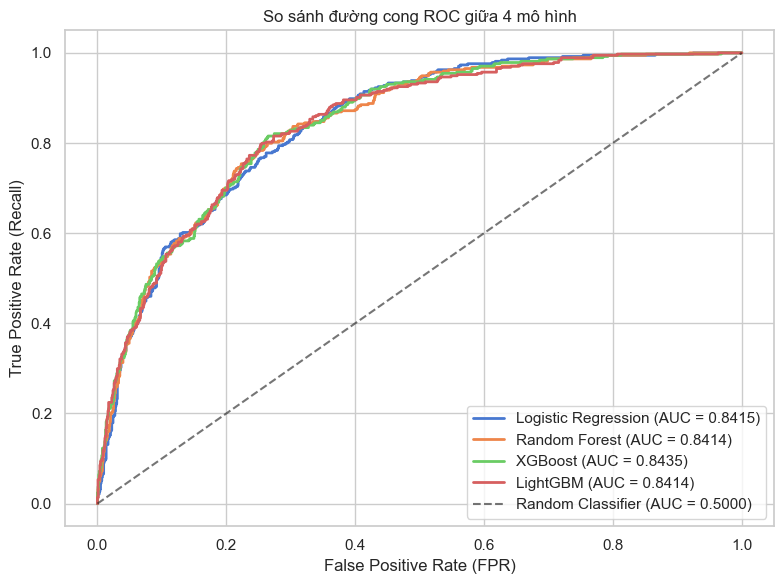

In [10]:
plt.figure(figsize=(8, 6))
for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc_val:.4f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Random Classifier (AUC = 0.5000)")
plt.title("So sánh đường cong ROC giữa 4 mô hình")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 4.2 Ma trận nhầm lẫn (Confusion Matrix) & Feature Importance của XGBoost

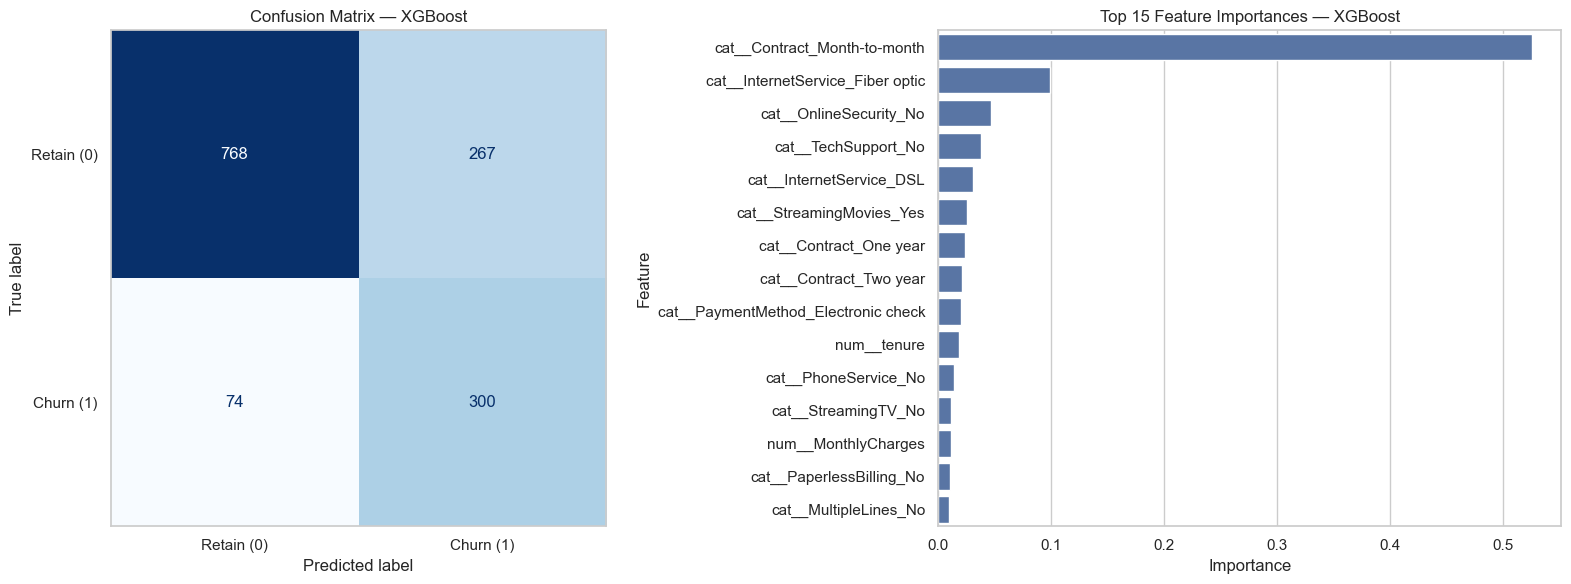

In [11]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = trained_pipelines[best_model_name]
best_cm = confusion_matrix(y_test, predictions[best_model_name])

encoded_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()
importances = best_pipeline.named_steps["classifier"].feature_importances_
importance_df = (
    pd.DataFrame({"Feature": encoded_names, "Importance": importances})
    .sort_values(by="Importance", ascending=False)
    .head(15)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=best_cm,
    display_labels=["Retain (0)", "Churn (1)"],
)
disp.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion Matrix — {best_model_name}")
axes[0].grid(False)

sns.barplot(data=importance_df, x="Importance", y="Feature", ax=axes[1], color="#4C72B0")
axes[1].set_title(f"Top 15 Feature Importances — {best_model_name}")

plt.tight_layout()
plt.show()

### 4.3 Giải thích mô hình với TreeSHAP (Global & Local Explainability)

- **Global (Beeswarm Plot):** Cho thấy mức độ quan trọng và chiều tác động (tăng/giảm xác suất Churn) của từng đặc trưng trên toàn bộ tập kiểm thử.
- **Local (Waterfall Plot):** Giải thích cụ thể lý do đẩy xác suất rời bỏ lên cao cho một khách hàng rủi ro cao, đồng bộ trực tiếp với cơ chế XAI của hệ thống API.

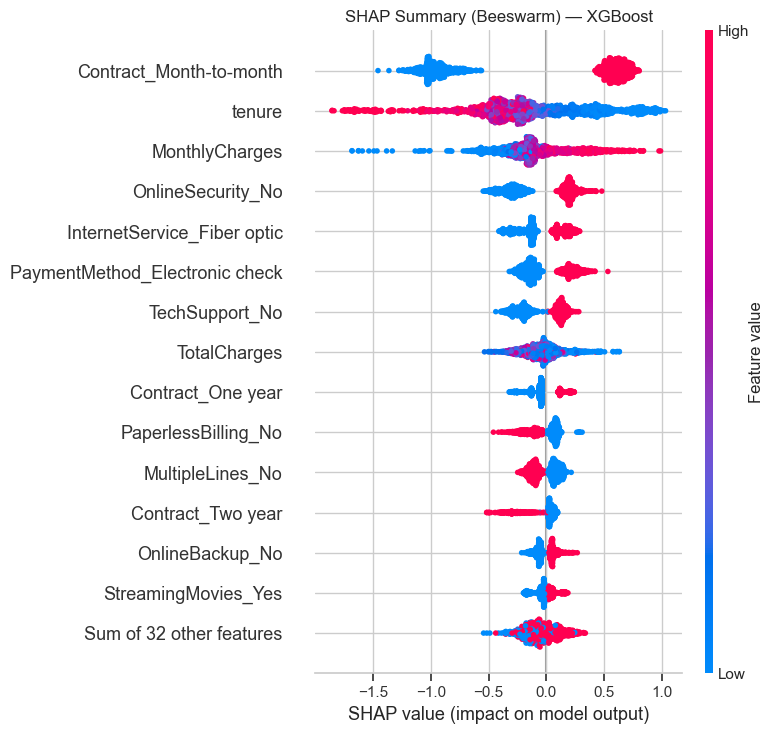

Khách hàng rủi ro cao nhất tập Test (index=1090): Xác suất Churn = 97.00%, Thực tế = 1


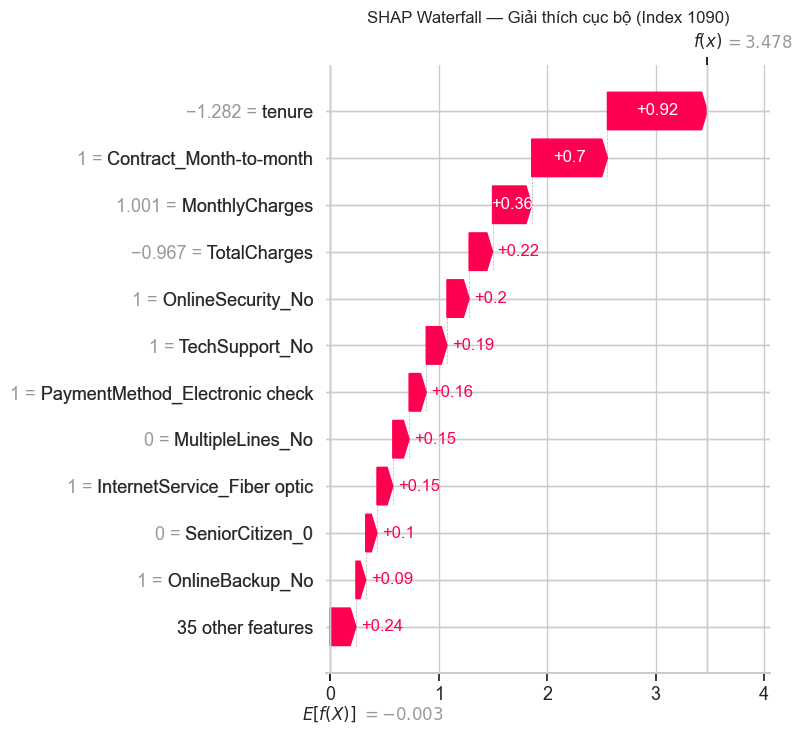

In [12]:
preprocessor = best_pipeline.named_steps["preprocessor"]
classifier = best_pipeline.named_steps["classifier"]

X_test_transformed = preprocessor.transform(X_test)
clean_feature_names = [
    name.split("__", 1)[-1] for name in preprocessor.get_feature_names_out()
]

contribs = classifier.get_booster().predict(
    xgb.DMatrix(X_test_transformed), pred_contribs=True
)
shap_values = contribs[:, :-1]
base_values = contribs[:, -1]

shap_explanation = shap.Explanation(
    values=shap_values,
    base_values=base_values,
    data=X_test_transformed,
    feature_names=clean_feature_names,
)

plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_explanation, max_display=15, show=False)
plt.title(f"SHAP Summary (Beeswarm) — {best_model_name}")
plt.tight_layout()
plt.show()

high_risk_idx = int(np.argmax(probabilities[best_model_name]))
high_risk_prob = float(probabilities[best_model_name][high_risk_idx])
print(
    f"Khách hàng rủi ro cao nhất tập Test (index={high_risk_idx}): "
    f"Xác suất Churn = {high_risk_prob:.2%}, Thực tế = {y_test.iloc[high_risk_idx]}"
)

plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_explanation[high_risk_idx], max_display=12, show=False)
plt.title(f"SHAP Waterfall — Giải thích cục bộ (Index {high_risk_idx})")
plt.tight_layout()
plt.show()